# Lab 11: Attention

Name: Abbas Abdelaziz Al-Tunayan  
Student ID: 2240004112


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

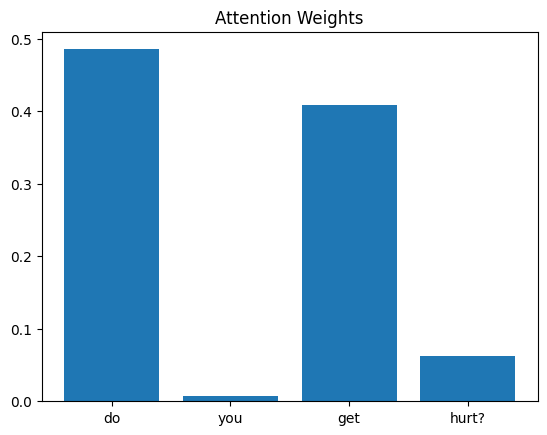

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question 30: highest attention -> 'to' (0.750) | predicted answer_id: 10 | true answer_id: 2
Question 90: highest attention -> 'are' (0.469) | predicted answer_id: 3 | true answer_id: 6
Question 150: highest attention -> 'to' (0.605) | predicted answer_id: 10 | true answer_id: 10


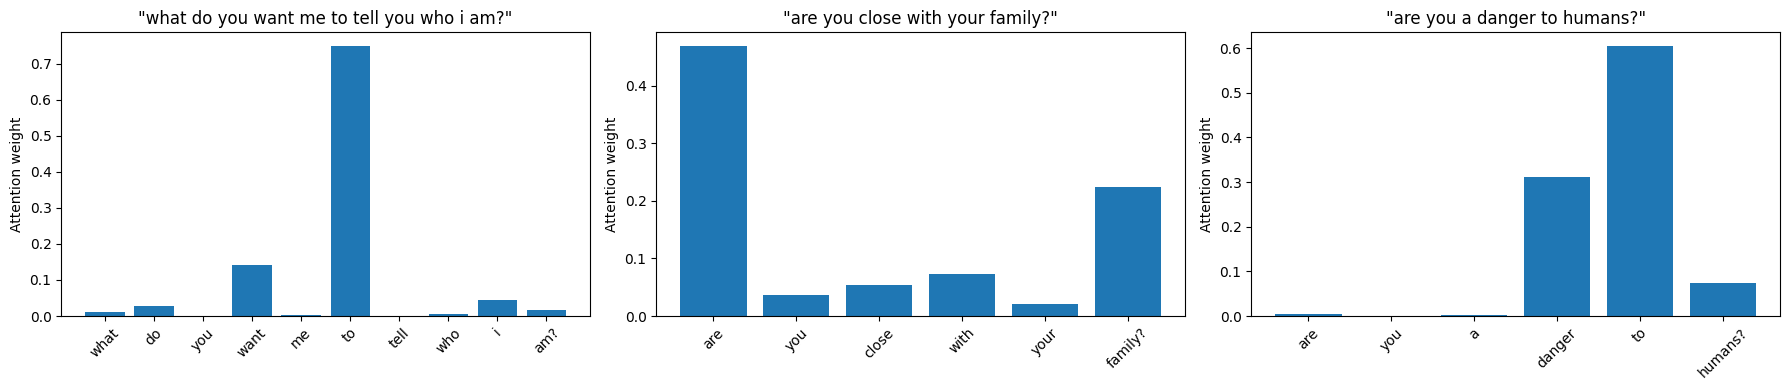

In [7]:
# Task 1: attention weights for three different questions
question_ids = [30, 90, 150]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, idx in zip(axes, question_ids):
    words = df["question"][idx].split()
    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])
    w = weights[0, :len(words)].tolist()

    ax.bar(words, w)
    ax.set_title(f'"{df["question"][idx]}"')
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=45)

    top = words[w.index(max(w))]
    print(f"Question {idx}: highest attention -> '{top}' ({max(w):.3f}) | predicted answer_id: {prediction.argmax().item()} | true answer_id: {y[idx].item()}")

plt.tight_layout()
plt.show()


**Answer (Task 1):** The highest-attention words were "to" in *"what do you want me to tell you who i am?"* (0.750), "are" in *"are you close with your family?"* (0.469), and "to" in *"are you a danger to humans?"* (0.605).

Only partly. In the third question the model also gives clear weight to "danger" (0.31), which is the word that carries the meaning. In the second question "family?" gets the second-highest weight (0.22), which is also meaningful. However, the top word is often a function word ("to", "are"), which does not carry the meaning of the question. So the highest weights do not always land on the content words a human would pick. This is a small RNN trained for only 50 epochs on 168 short questions, so it can reach a prediction using word position and common words as shortcuts. Its predicted answers also did not match the true answer for two of the three questions (30 and 90), which agrees with the attention not being fully reliable here. The charts show where the model looked, not necessarily the word a person would call most important.


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 116: highest attention -> 'to' (0.571) | predicted answer_id: 10
Question 120: highest attention -> 'to' (0.860) | predicted answer_id: 10


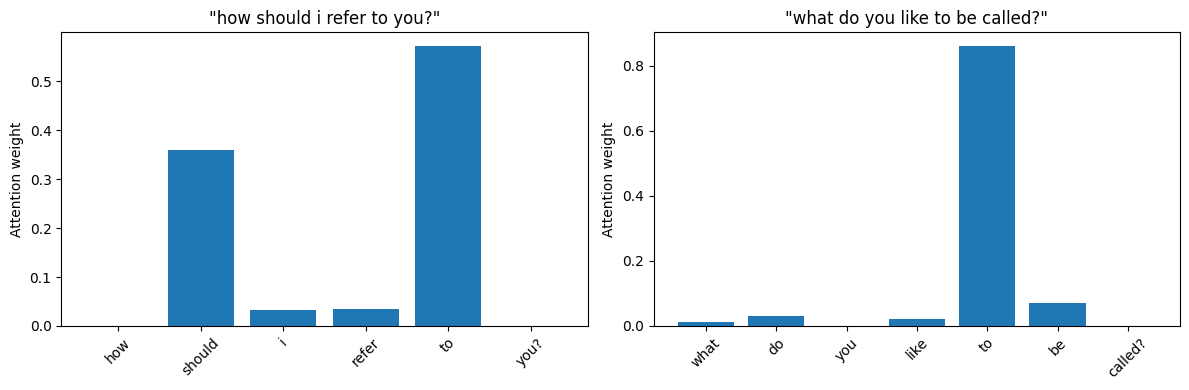

In [8]:
# Task 2: compare attention for two questions with similar meaning
pair = [116, 120]  # both ask for the assistant's name

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, idx in zip(axes, pair):
    words = df["question"][idx].split()
    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])
    w = weights[0, :len(words)].tolist()

    ax.bar(words, w)
    ax.set_title(f'"{df["question"][idx]}"')
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=45)

    top = words[w.index(max(w))]
    print(f"Question {idx}: highest attention -> '{top}' ({max(w):.3f}) | predicted answer_id: {prediction.argmax().item()}")

plt.tight_layout()
plt.show()


**Answer (Task 2):** I compared *"how should i refer to you?"* and *"what do you like to be called?"*, which both ask for the assistant's name. Both questions put their highest attention on the same word, "to" (0.571 and 0.860), and the model predicted the same answer (answer_id 10) for both. The first question also gives noticeable weight to "should" (0.36), while the second puts almost all of its weight on "to".

So the model focuses on similar words, but not because it understands that the two questions mean the same thing. The shared word "to" is a common function word, and the model seems to rely on it as a shortcut. The predicted answer is also not the correct one for this group (the name answer is answer_id 8). This suggests that attention shows which input positions the model relies on when making a prediction. It does not by itself prove that the model understands meaning, and with a small model and small dataset the weights can pick up on frequent words instead of the words that matter.
